In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("D:\Project\Datasets\dataset\EEG_data.csv")
data_info = pd.read_csv("D:\Project\Datasets\dataset\demographic_info.csv")

In [3]:
data.shape

(12811, 15)

In [4]:
data.head(5000)

,SubjectID,VideoID,Attention,Mediation,Raw,Delta,Theta,Alpha1,Alpha2,Beta1,Beta2,Gamma1,Gamma2,predefinedlabel,user-definedlabeln
0,0.0,0.0,56.0,43.0,278.0,301963.0,90612.0,33735.0,23991.0,27946.0,45097.0,33228.0,8293.0,0.0,0.0
1,0.0,0.0,40.0,35.0,-50.0,73787.0,28083.0,1439.0,2240.0,2746.0,3687.0,5293.0,2740.0,0.0,0.0
2,0.0,0.0,47.0,48.0,101.0,758353.0,383745.0,201999.0,62107.0,36293.0,130536.0,57243.0,25354.0,0.0,0.0
3,0.0,0.0,47.0,57.0,-5.0,2012240.0,129350.0,61236.0,17084.0,11488.0,62462.0,49960.0,33932.0,0.0,0.0
4,0.0,0.0,44.0,53.0,-8.0,1005145.0,354328.0,37102.0,88881.0,45307.0,99603.0,44790.0,29749.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,3.0,8.0,37.0,40.0,283.0,1081290.0,276307.0,21843.0,21312.0,22169.0,10338.0,23893.0,4034.0,1.0,1.0
4996,3.0,8.0,41.0,48.0,69.0,1372118.0,45024.0,45600.0,27894.0,7830.0,10085.0,4522.0,2321.0,1.0,1.0
4997,3.0,8.0,43.0,63.0,103.0,488255.0,18540.0,60894.0,31418.0,54846.0,18216.0,6261.0,3300.0,1.0,1.0
4998,3.0,8.0,53.0,78.0,68.0,1043412.0,199014.0,137677.0,34119.0,15218.0,22357.0,10602.0,5356.0,1.0,1.0


In [5]:
data_info

,subject ID,age,ethnicity,gender
0,0,25,Han Chinese,M
1,1,24,Han Chinese,M
2,2,31,English,M
3,3,28,Han Chinese,F
4,4,24,Bengali,M
5,5,24,Han Chinese,M
6,6,24,Han Chinese,M
7,7,25,Han Chinese,M
8,8,25,Han Chinese,M
9,9,24,Han Chinese,F


In [6]:
data_info.rename(columns={'subject ID':'SubjectID'}, inplace=True)

In [7]:
data['Sample'] = data.reset_index().index +0.5

In [8]:
data_info = data_info.merge(data, on='SubjectID')

In [9]:
data_info.head()

,SubjectID,age,ethnicity,gender,VideoID,Attention,Mediation,Raw,Delta,Theta,Alpha1,Alpha2,Beta1,Beta2,Gamma1,Gamma2,predefinedlabel,user-definedlabeln,Sample
0,0,25,Han Chinese,M,0.0,56.0,43.0,278.0,301963.0,90612.0,33735.0,23991.0,27946.0,45097.0,33228.0,8293.0,0.0,0.0,0.5
1,0,25,Han Chinese,M,0.0,40.0,35.0,-50.0,73787.0,28083.0,1439.0,2240.0,2746.0,3687.0,5293.0,2740.0,0.0,0.0,1.5
2,0,25,Han Chinese,M,0.0,47.0,48.0,101.0,758353.0,383745.0,201999.0,62107.0,36293.0,130536.0,57243.0,25354.0,0.0,0.0,2.5
3,0,25,Han Chinese,M,0.0,47.0,57.0,-5.0,2012240.0,129350.0,61236.0,17084.0,11488.0,62462.0,49960.0,33932.0,0.0,0.0,3.5
4,0,25,Han Chinese,M,0.0,44.0,53.0,-8.0,1005145.0,354328.0,37102.0,88881.0,45307.0,99603.0,44790.0,29749.0,0.0,0.0,4.5


In [10]:
data_info.rename(columns={' gender':'Gender'}, inplace=True)
data_info.rename(columns={' age':'Age'}, inplace=True)
data_info.rename(columns={' ethnicity':'Ethnicity'}, inplace=True)

In [11]:
data_info['Gender'] = data_info['Gender'].replace({'M':1, 'F':0})
data_info['Ethnicity'] = data_info['Ethnicity'].replace({'Han Chinese':0,'Bengali':1,'English':2})

In [12]:
data_info.head()

,SubjectID,Age,Ethnicity,Gender,VideoID,Attention,Mediation,Raw,Delta,Theta,Alpha1,Alpha2,Beta1,Beta2,Gamma1,Gamma2,predefinedlabel,user-definedlabeln,Sample
0,0,25,0,1,0.0,56.0,43.0,278.0,301963.0,90612.0,33735.0,23991.0,27946.0,45097.0,33228.0,8293.0,0.0,0.0,0.5
1,0,25,0,1,0.0,40.0,35.0,-50.0,73787.0,28083.0,1439.0,2240.0,2746.0,3687.0,5293.0,2740.0,0.0,0.0,1.5
2,0,25,0,1,0.0,47.0,48.0,101.0,758353.0,383745.0,201999.0,62107.0,36293.0,130536.0,57243.0,25354.0,0.0,0.0,2.5
3,0,25,0,1,0.0,47.0,57.0,-5.0,2012240.0,129350.0,61236.0,17084.0,11488.0,62462.0,49960.0,33932.0,0.0,0.0,3.5
4,0,25,0,1,0.0,44.0,53.0,-8.0,1005145.0,354328.0,37102.0,88881.0,45307.0,99603.0,44790.0,29749.0,0.0,0.0,4.5


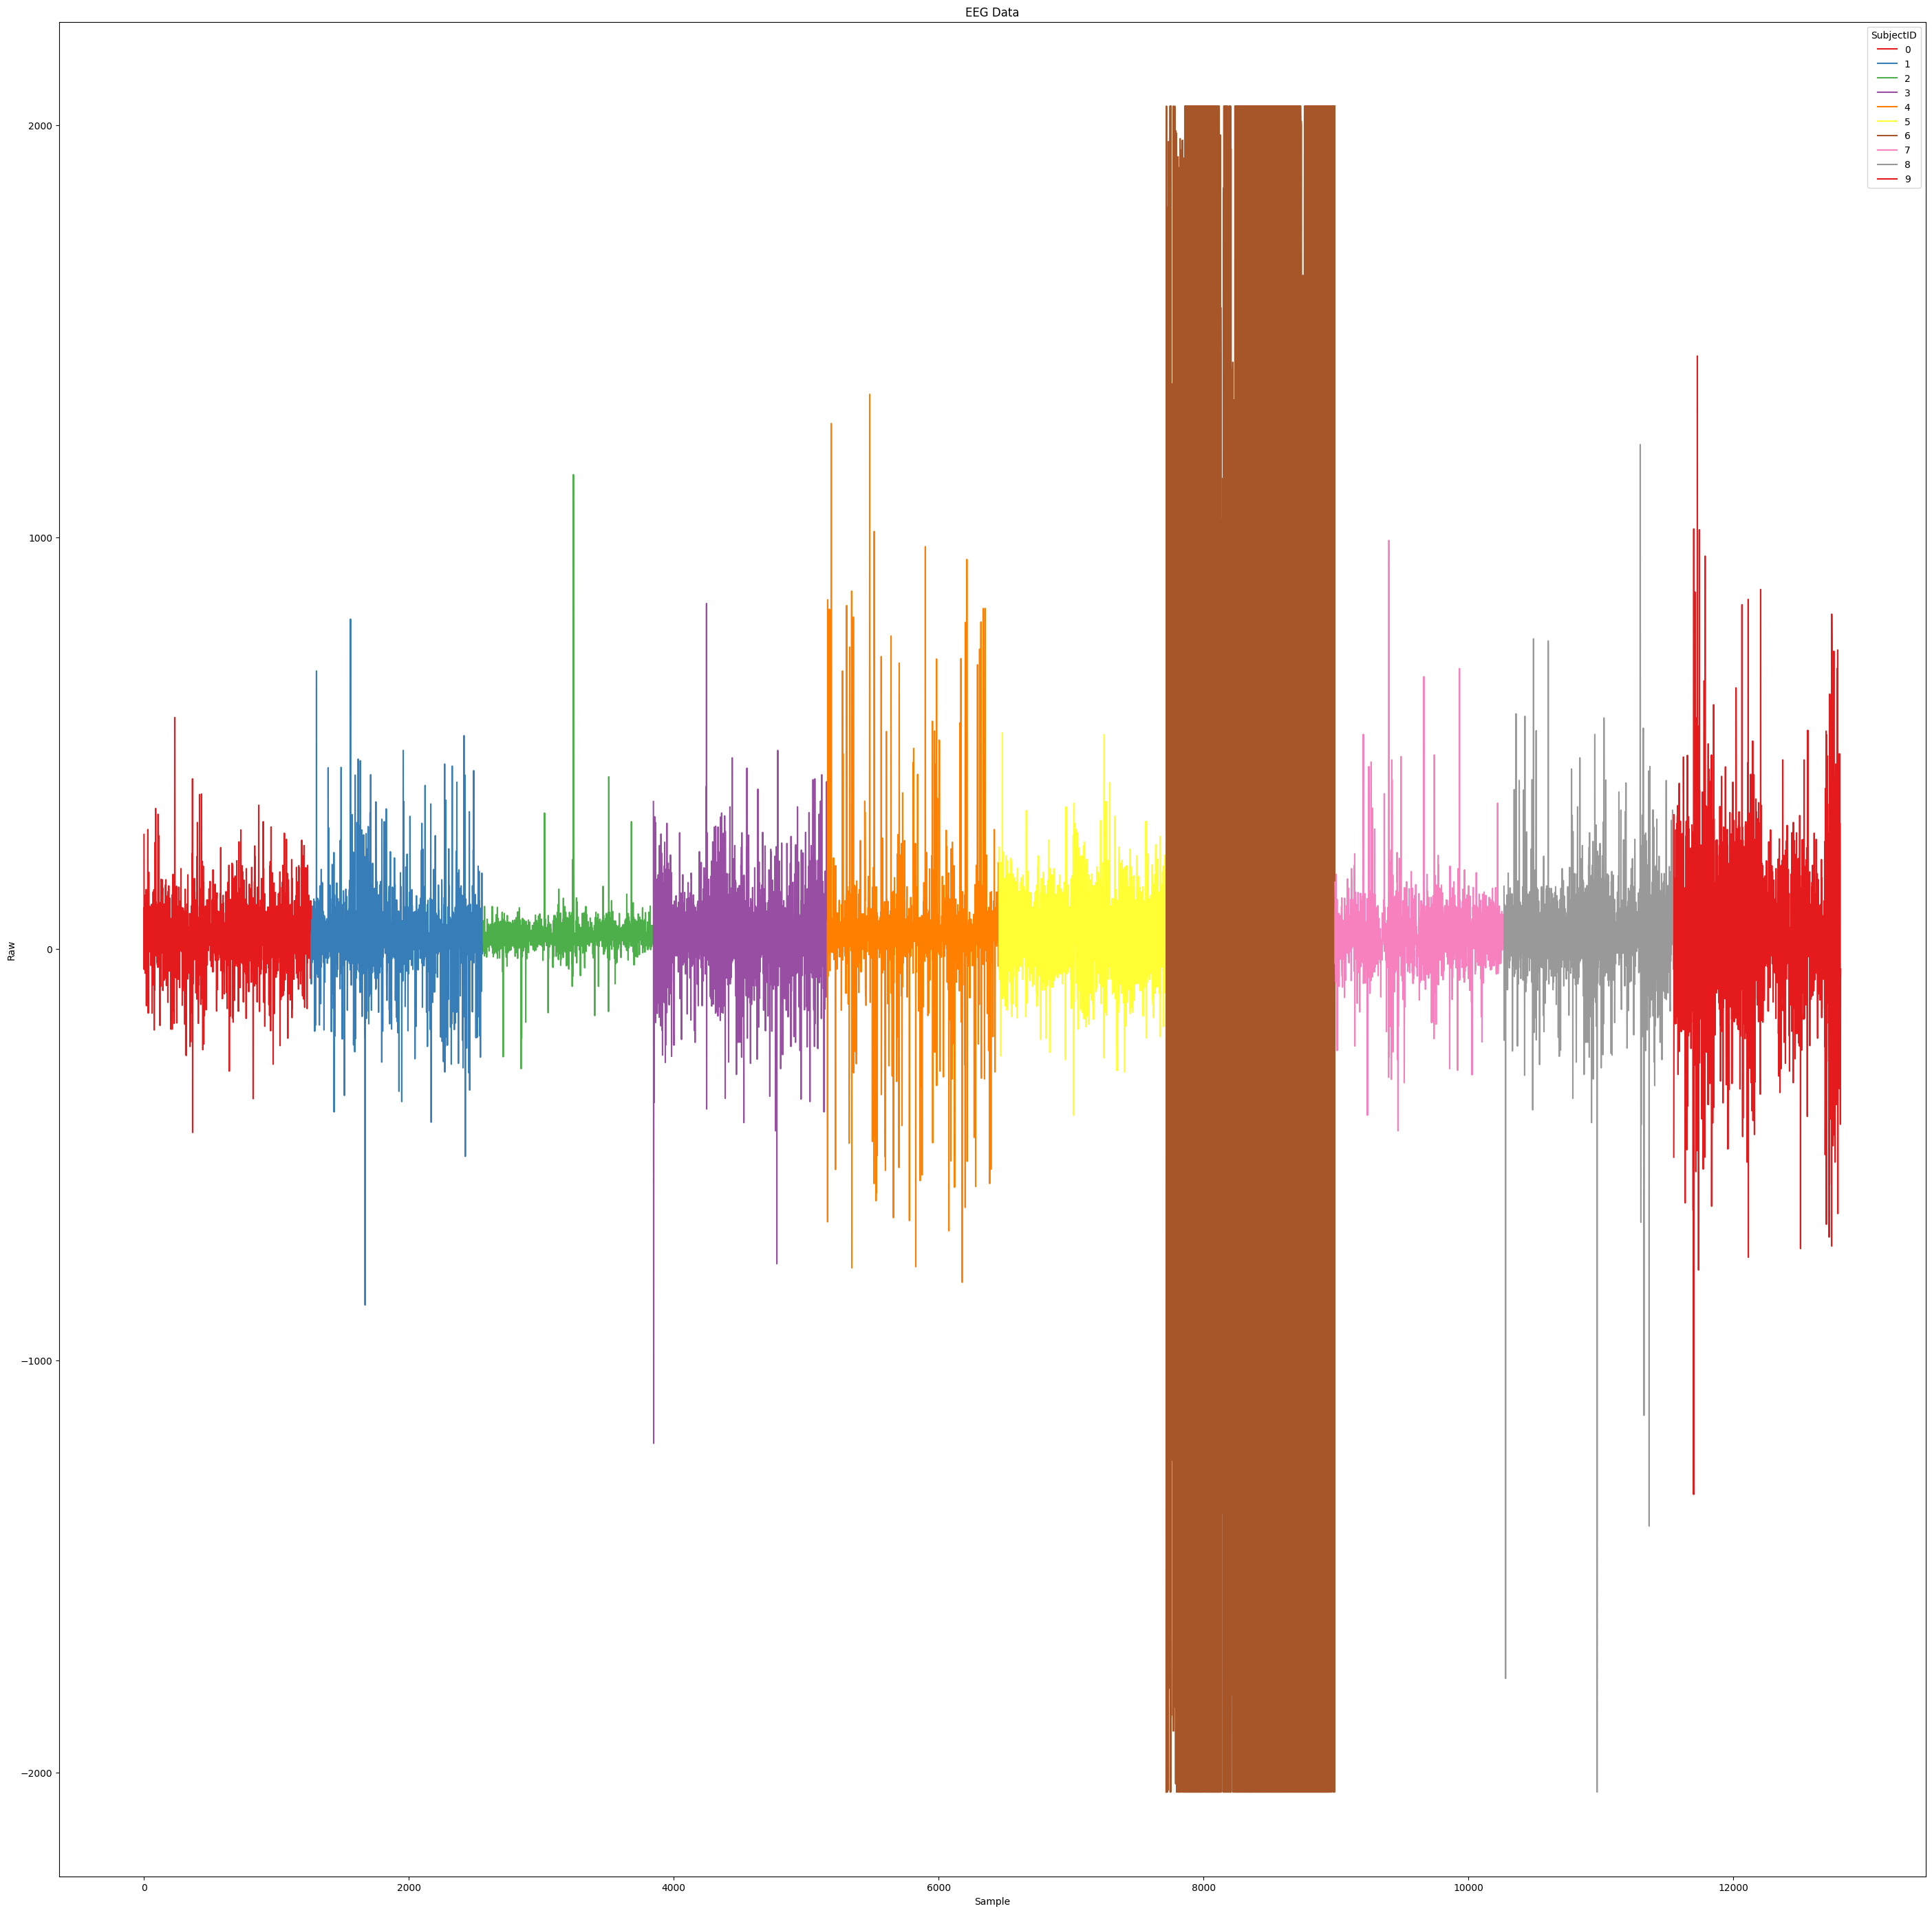

In [13]:
plt.figure(figsize=(35, 35))


sns.lineplot(data = data_info, x='Sample', y='Raw', hue='SubjectID', palette='Set1')

plt.xlabel('Sample')
plt.ylabel('Raw')
plt.title('EEG Data')



plt.show()

In [14]:
data_info = data_info[data_info['SubjectID'] != 6]
data_info.reset_index(drop=True, inplace=True)

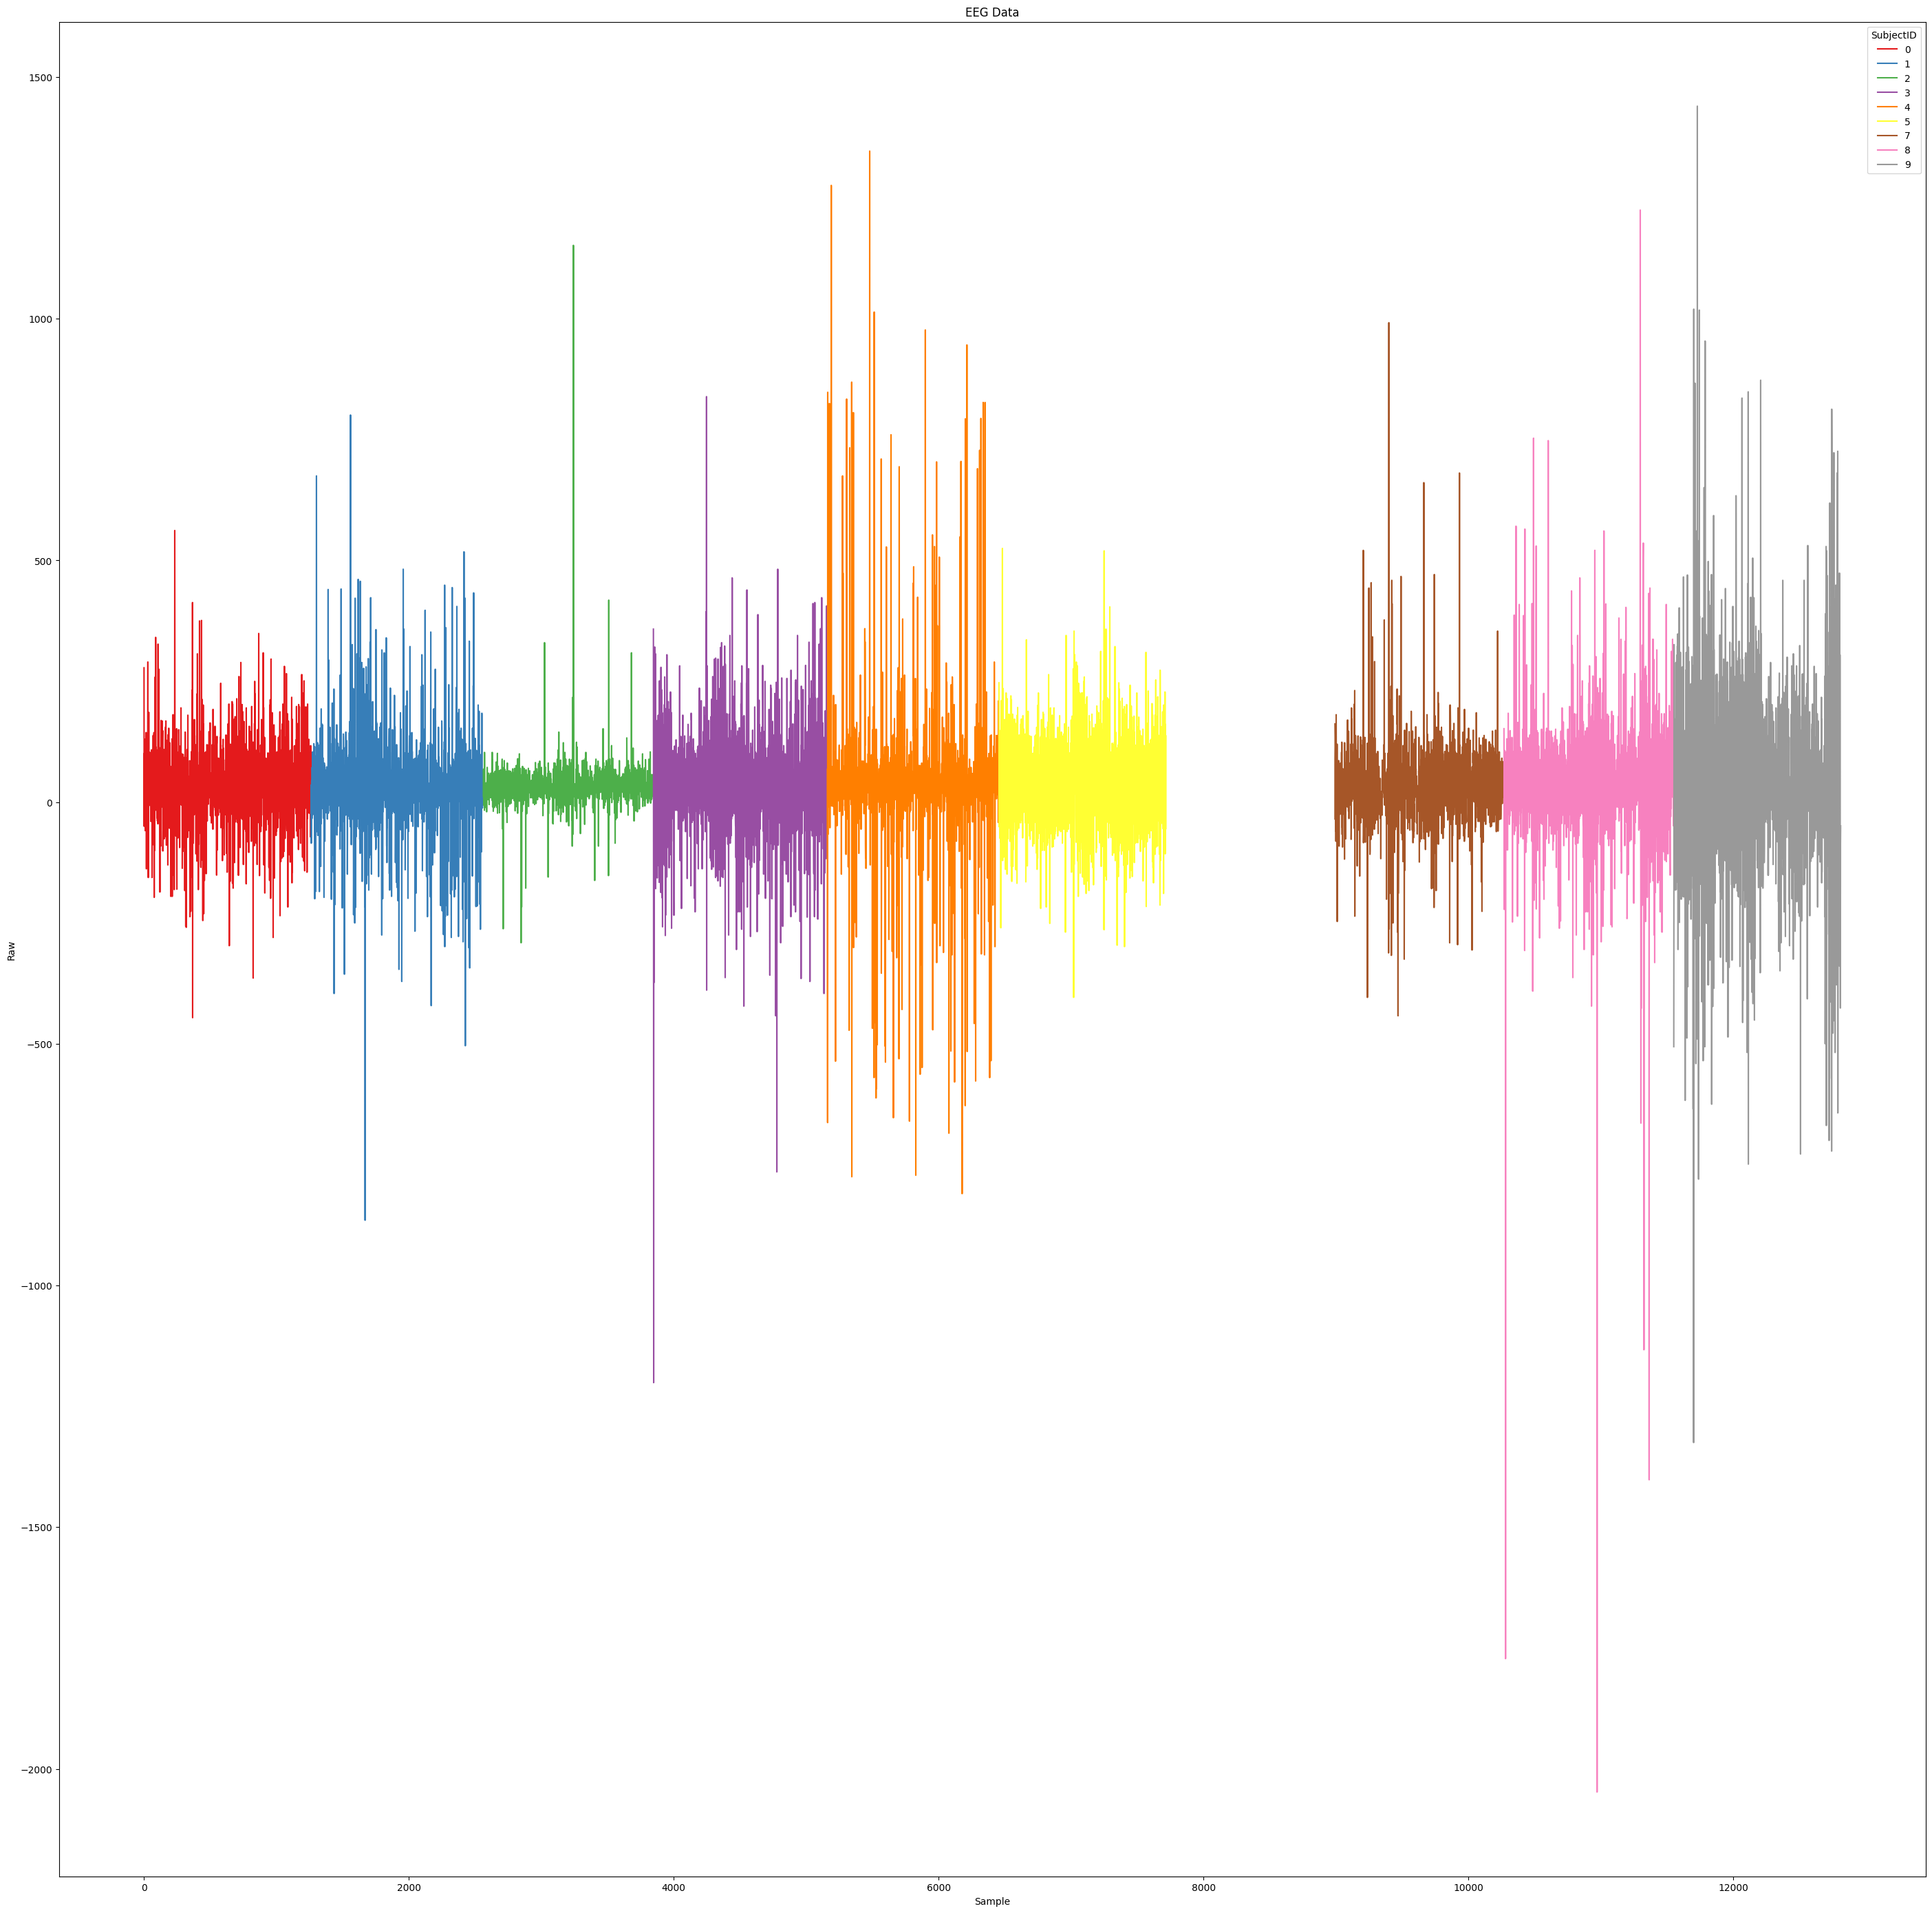

In [15]:
plt.figure(figsize=(35, 35))


sns.lineplot(data = data_info, x='Sample', y='Raw', hue='SubjectID', palette='Set1')

plt.xlabel('Sample')
plt.ylabel('Raw')  
plt.title('EEG Data')

plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


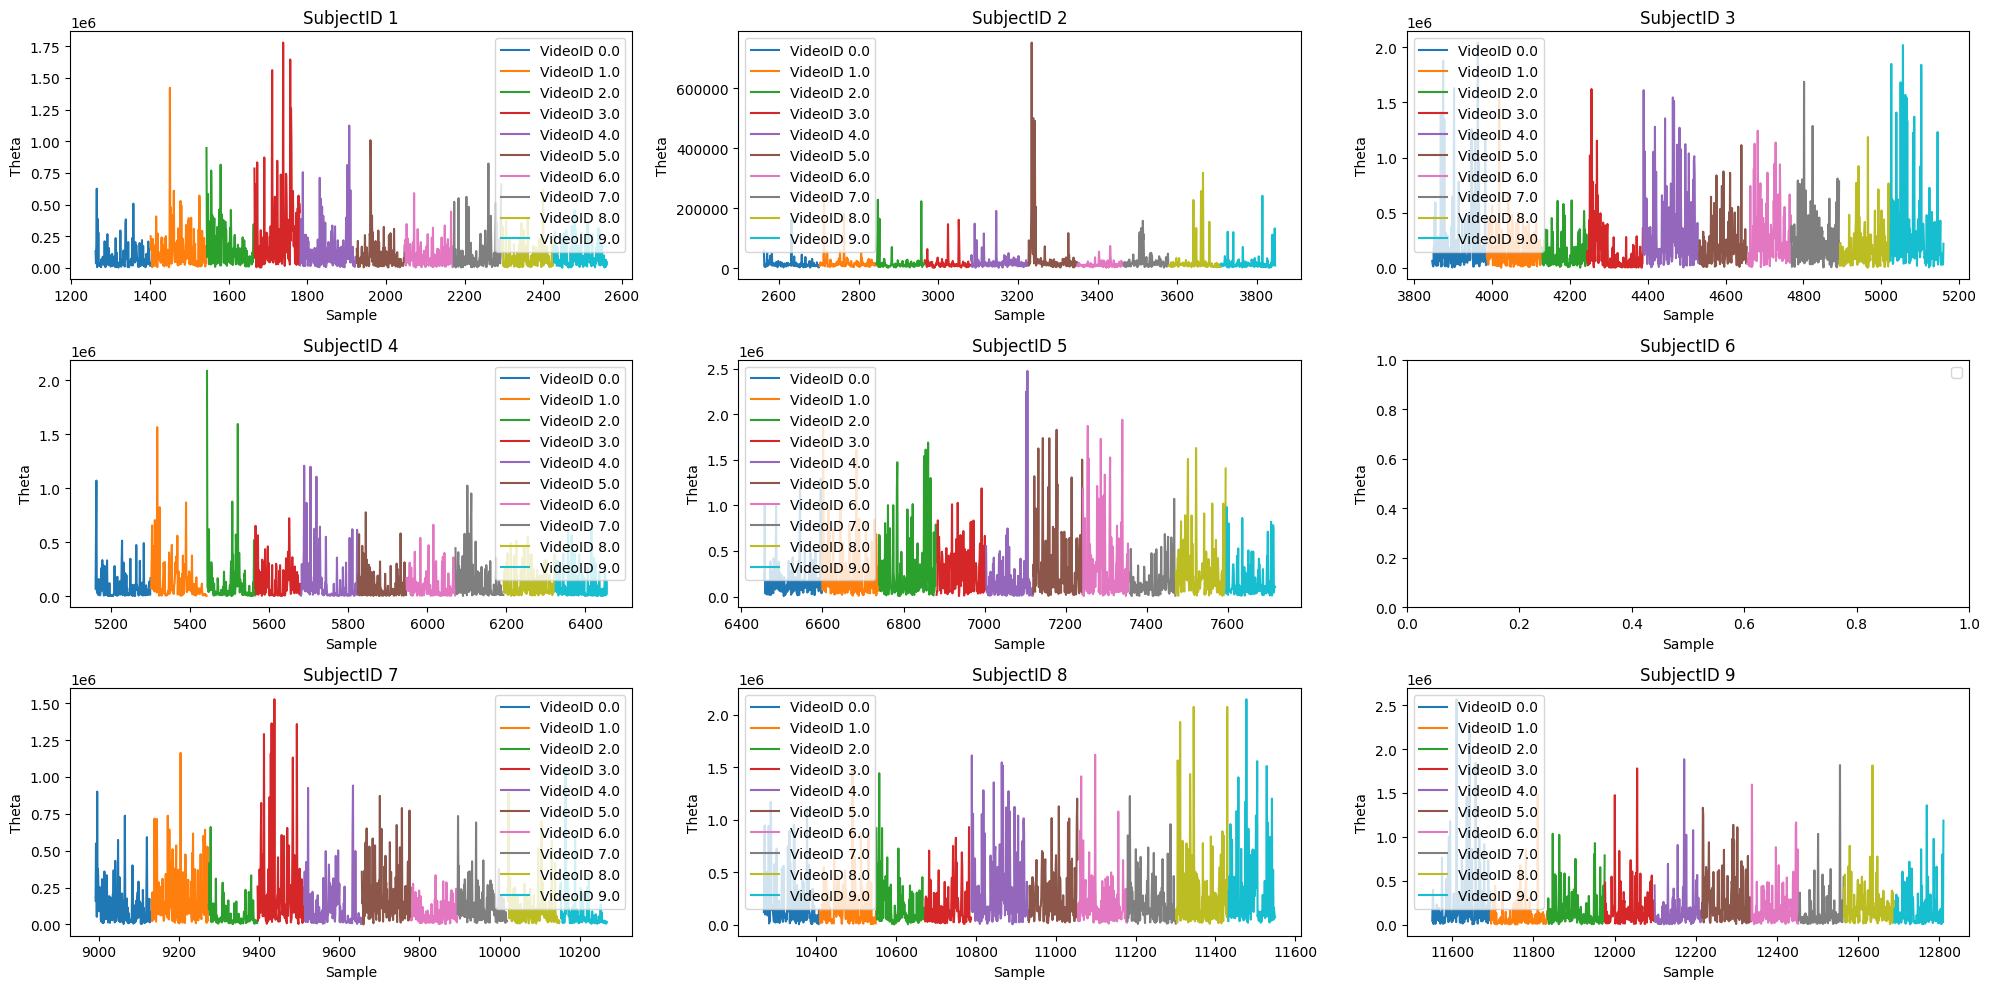

In [16]:
filtered_df = data_info[data_info['SubjectID'].between(0, 10)]

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 10))

for i, ax in enumerate(axes.flatten()):
    subject_data = filtered_df[filtered_df['SubjectID'] == i+1]
    for video_id, group_data in subject_data.groupby('VideoID'):
        ax.plot(group_data['Sample'], group_data['Theta'], label=f'VideoID {video_id}')
    ax.set_xlabel('Sample')
    ax.set_ylabel('Theta')
    ax.set_title(f'SubjectID {i+1}')
    ax.legend()

plt.tight_layout()

plt.show()

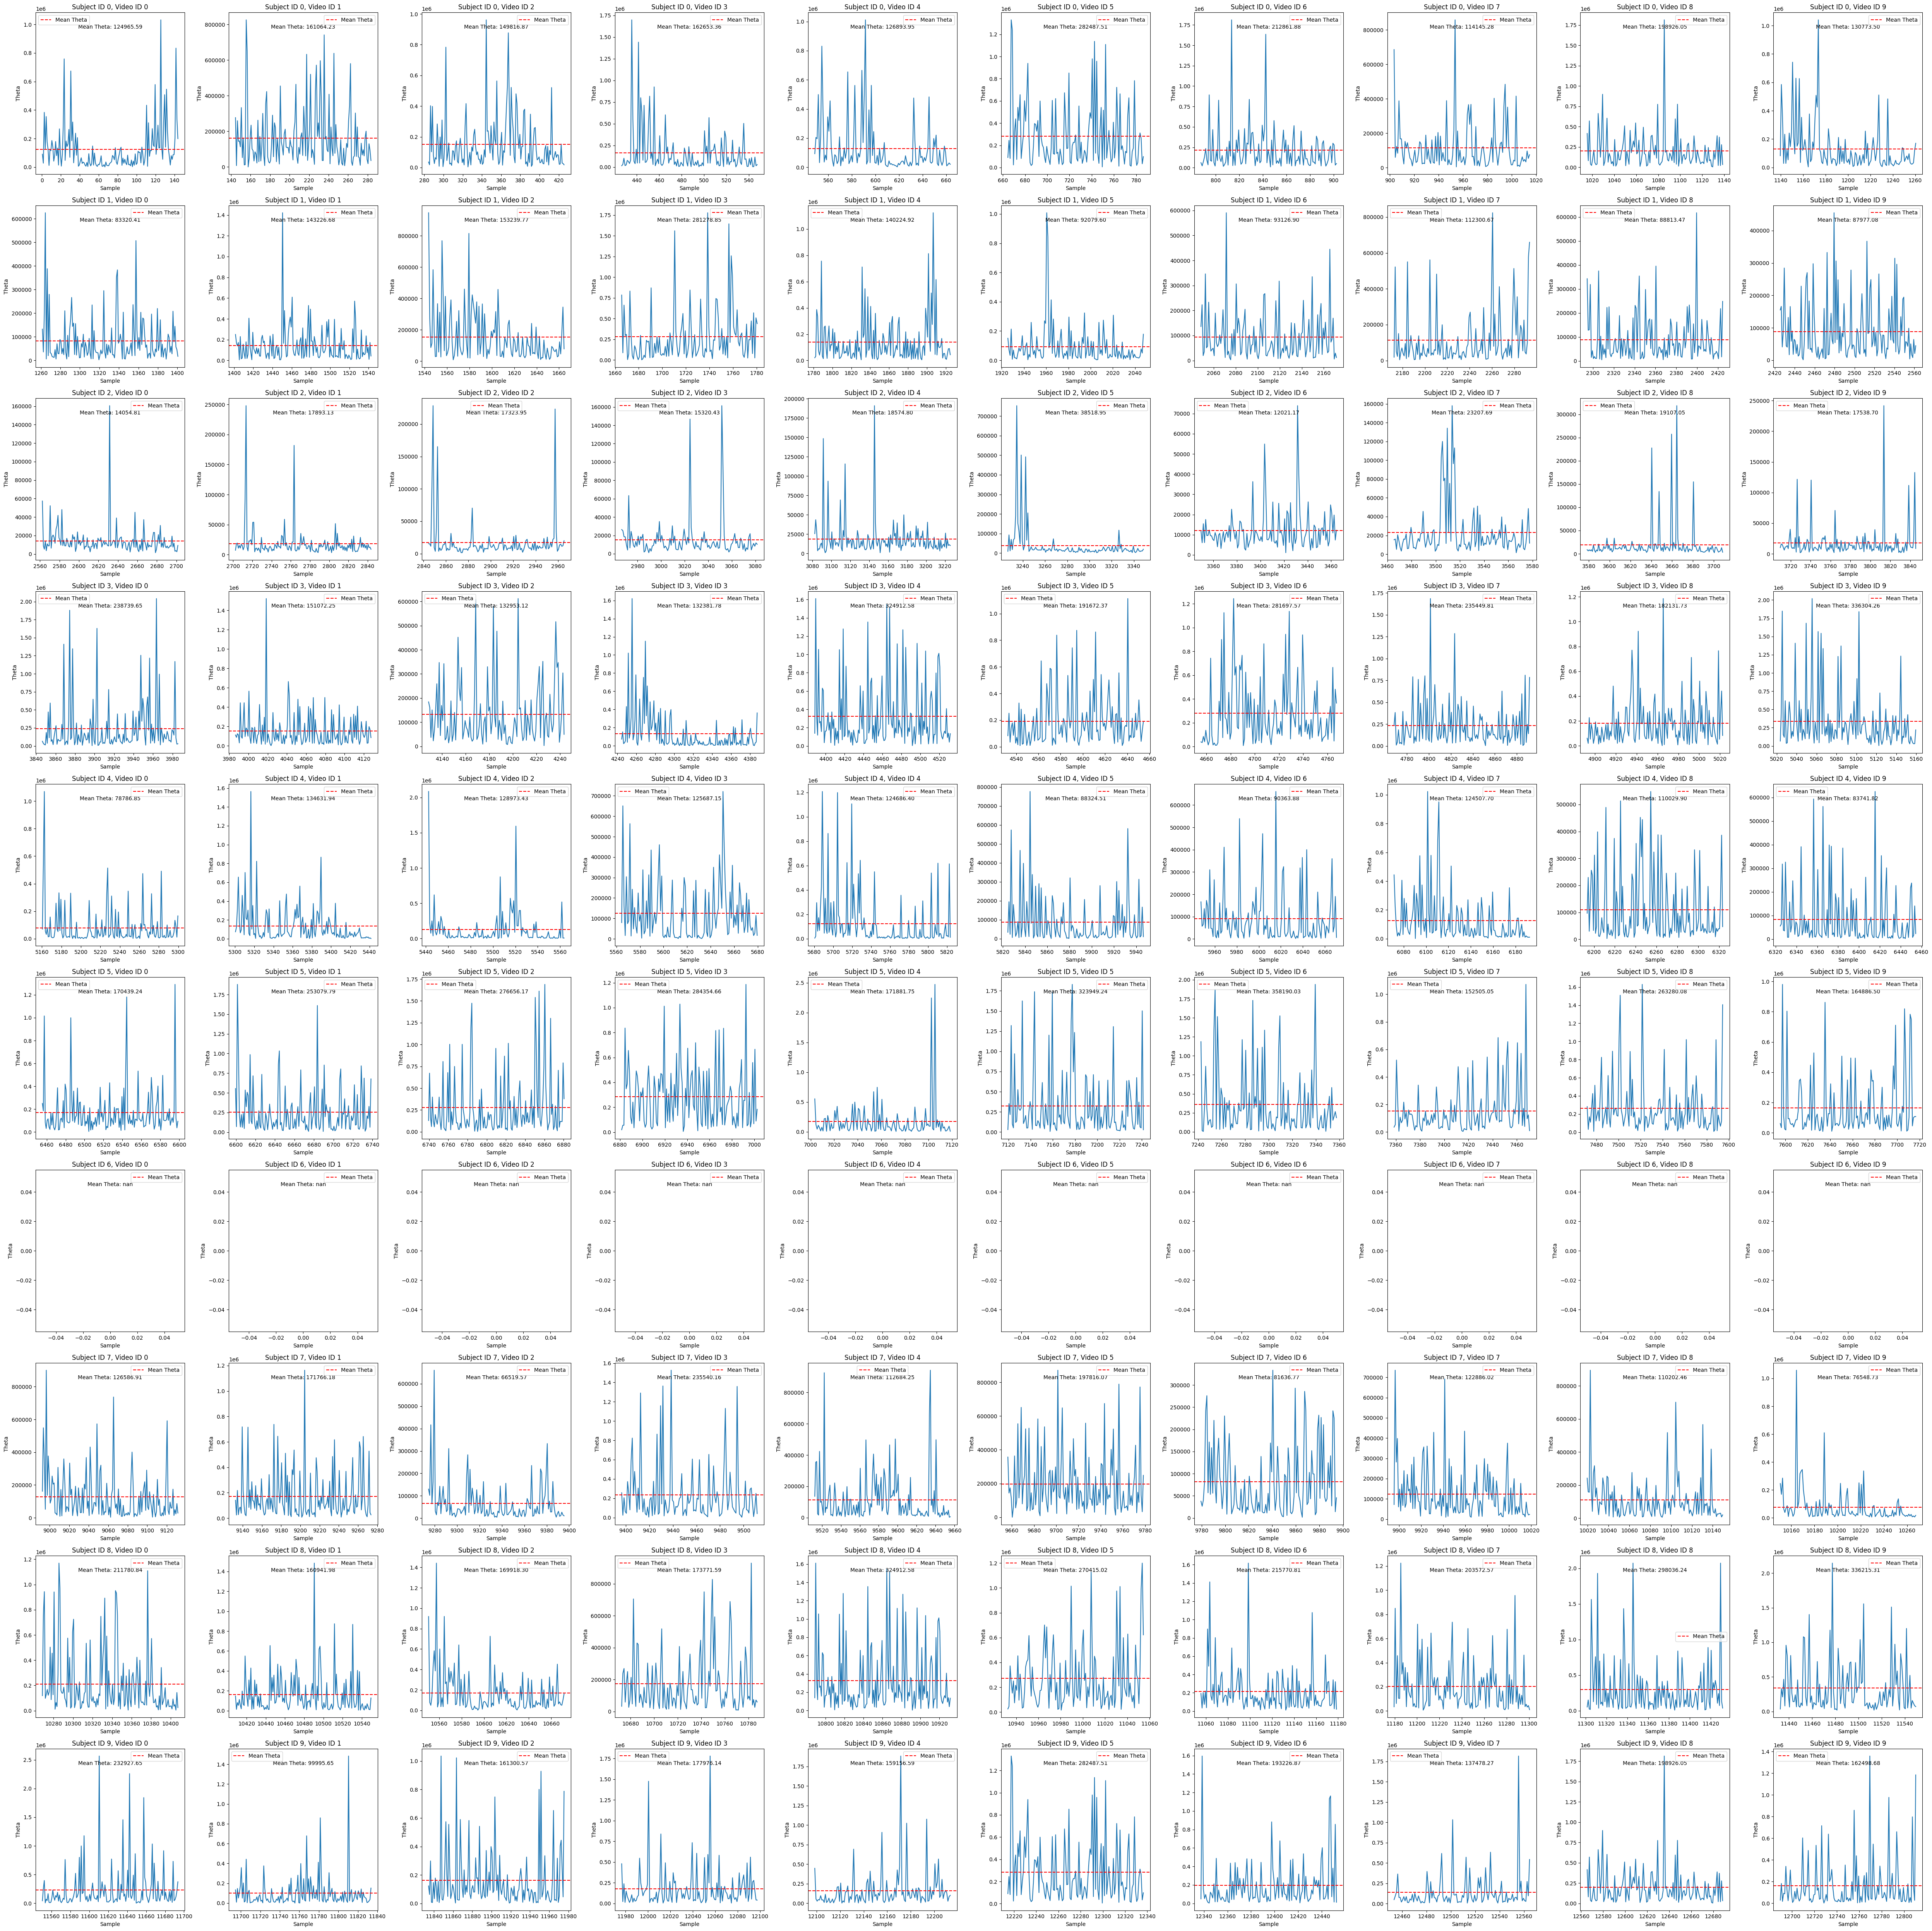

In [17]:
fig, axes = plt.subplots(nrows=10, ncols=10, figsize=(50, 50))

for i, ax_row in enumerate(axes):
    for j, ax in enumerate(ax_row):
        subject_id = i + 0
        video_id = j + 0 
        subset_df = data_info[(data_info['SubjectID'] == subject_id) & (data_info['VideoID'] == video_id)]
        sns.lineplot(data=subset_df, x='Sample', y='Theta', ax=ax)
        ax.set_title(f'Subject ID {subject_id}, Video ID {video_id}')
        ax.set_xlabel('Sample')
        ax.set_ylabel('Theta')
        mean_theta = subset_df['Theta'].mean()
        ax.axhline(mean_theta, color='red', linestyle='--', label='Mean Theta')
        ax.legend()
        ax.text(0.5, 0.9, f'Mean Theta: {mean_theta:.2f}', transform=ax.transAxes, ha='center')
        
plt.tight_layout()

plt.show()


In [18]:
mean_theta_list = []
for subject_id in data_info['SubjectID'].unique():
    subset_df = data_info[data_info['SubjectID'] == subject_id]
    mean_theta = subset_df['Theta'].mean()
    mean_theta_list.append((subject_id, mean_theta))

mean_theta_list.sort(key=lambda x: x[1], reverse=True)

for subject_id, mean_theta in mean_theta_list:
    print(f"Subject ID {subject_id}: Mean Theta = {mean_theta:.2f}")

Subject ID 5: Mean Theta = 241902.46
Subject ID 8: Mean Theta = 236931.88
Subject ID 3: Mean Theta = 221221.47
Subject ID 9: Mean Theta = 180547.52
Subject ID 0: Mean Theta = 165919.79
Subject ID 7: Mean Theta = 130318.12
Subject ID 1: Mean Theta = 125888.29
Subject ID 4: Mean Theta = 108926.85
Subject ID 2: Mean Theta = 19263.66


In [19]:
mean_values = []

for subject_id in range(10):
    for video_id in range(10):
        subset_df = data_info[(data_info['SubjectID'] == subject_id) & (data_info['VideoID'] == video_id)]
        mean_theta1 = subset_df['Theta'].mean()
        mean_values.append((subject_id, video_id, mean_theta1))

mean_theta1_dict = {(subject_id, video_id): mean_theta1 for subject_id, video_id, mean_theta1 in mean_values}

data_info['MeanTheta'] = [mean_theta1_dict.get((subject_id, video_id), None) for subject_id, video_id in zip(data_info['SubjectID'], data_info['VideoID'])]

data_info.head(3000)

,SubjectID,Age,Ethnicity,Gender,VideoID,Attention,Mediation,Raw,Delta,Theta,Alpha1,Alpha2,Beta1,Beta2,Gamma1,Gamma2,predefinedlabel,user-definedlabeln,Sample,MeanTheta
0,0,25,0,1,0.0,56.0,43.0,278.0,301963.0,90612.0,33735.0,23991.0,27946.0,45097.0,33228.0,8293.0,0.0,0.0,0.5,124965.590278
1,0,25,0,1,0.0,40.0,35.0,-50.0,73787.0,28083.0,1439.0,2240.0,2746.0,3687.0,5293.0,2740.0,0.0,0.0,1.5,124965.590278
2,0,25,0,1,0.0,47.0,48.0,101.0,758353.0,383745.0,201999.0,62107.0,36293.0,130536.0,57243.0,25354.0,0.0,0.0,2.5,124965.590278
3,0,25,0,1,0.0,47.0,57.0,-5.0,2012240.0,129350.0,61236.0,17084.0,11488.0,62462.0,49960.0,33932.0,0.0,0.0,3.5,124965.590278
4,0,25,0,1,0.0,44.0,53.0,-8.0,1005145.0,354328.0,37102.0,88881.0,45307.0,99603.0,44790.0,29749.0,0.0,0.0,4.5,124965.590278
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2,31,2,1,3.0,43.0,54.0,37.0,21593.0,10915.0,1051.0,3754.0,6899.0,6239.0,1913.0,1591.0,0.0,0.0,2995.5,15320.431034
2996,2,31,2,1,3.0,37.0,44.0,43.0,8699.0,23159.0,2830.0,2247.0,4507.0,2736.0,1526.0,3385.0,0.0,0.0,2996.5,15320.431034
2997,2,31,2,1,3.0,27.0,47.0,38.0,7630.0,13412.0,1957.0,19099.0,4328.0,3123.0,3206.0,2329.0,0.0,0.0,2997.5,15320.431034
2998,2,31,2,1,3.0,35.0,43.0,9.0,9153.0,35115.0,6963.0,6902.0,9915.0,7574.0,2675.0,1536.0,0.0,0.0,2998.5,15320.431034


<function matplotlib.pyplot.show(close=None, block=None)>

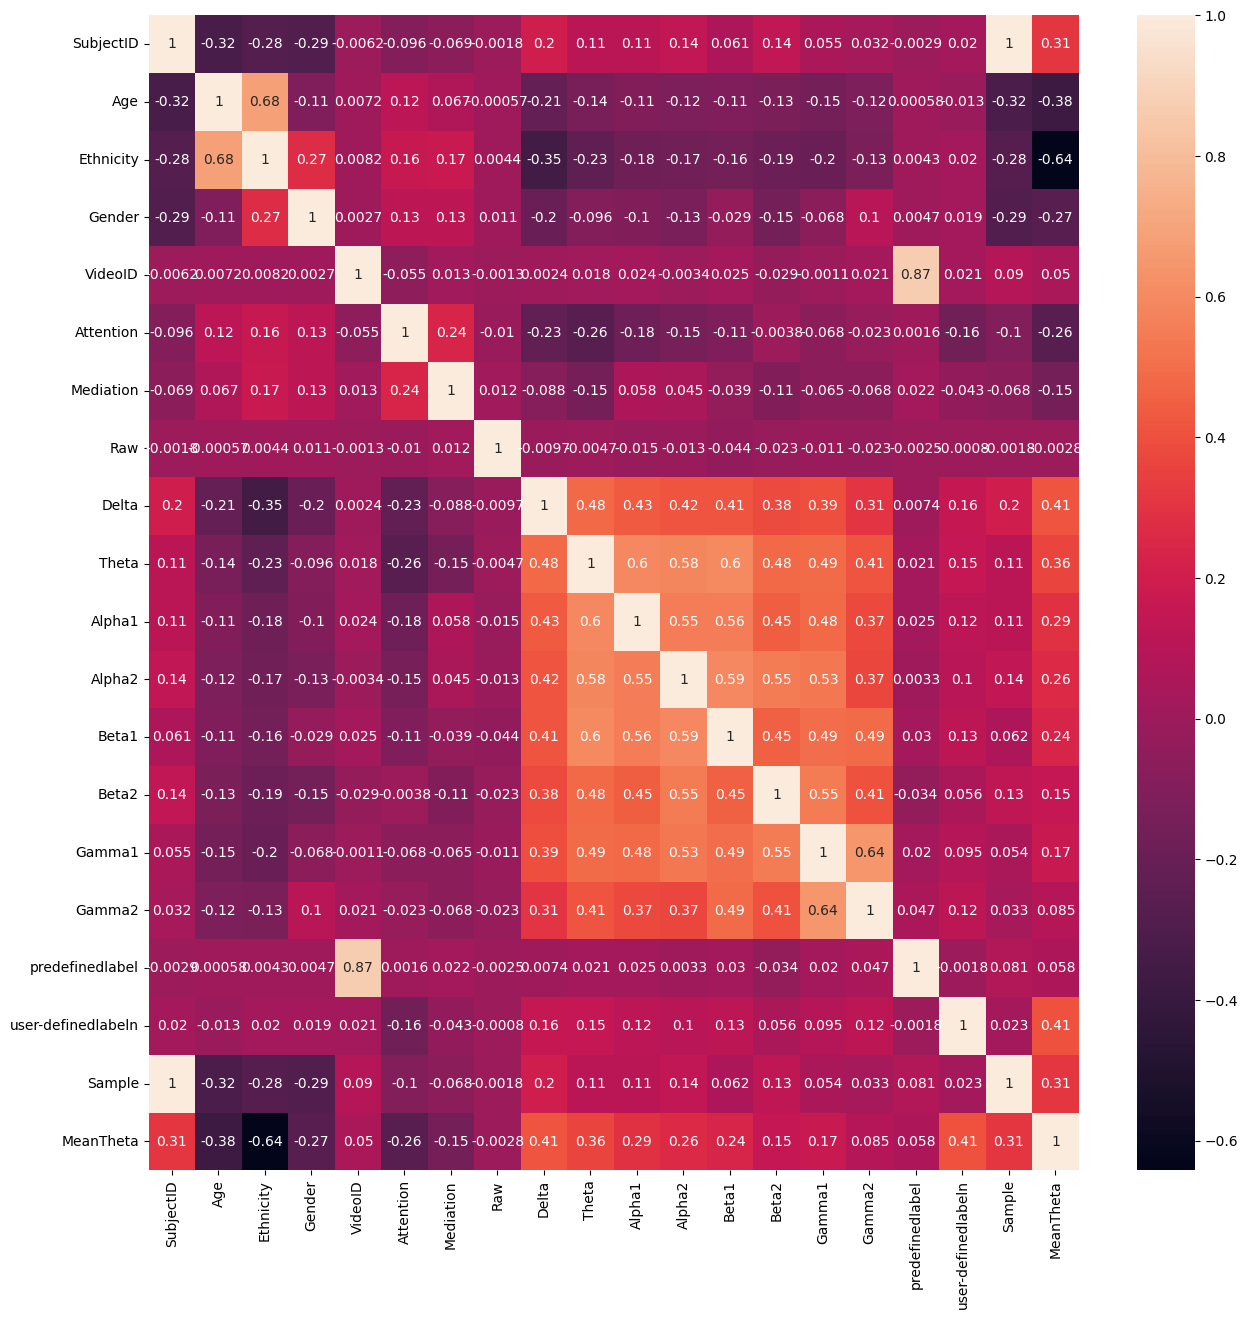

In [20]:
plt.figure(figsize = (15,15))
corr_matrix = data_info.corr()
sns.heatmap(corr_matrix, annot=True)
plt.show

In [21]:
data_info.to_csv('eda_data_info.csv',index=False)